# Ejercicio 1: Pronóstico de la calidad del aire en Pekín con una RNN


El objetivo de este ejercicio es **predecir la contaminación del aire** (partículas PM2.5) en el distrito de Nongzhanguan (Pekín, China) usando una **red neuronal recurrente (RNN)**.

Para ello le daremos a la red las mediciones de las últimas **12 horas** y ella intentará pronosticar cuál será la medición de la **siguiente hora**. Repitiendo este proceso, generaremos un pronóstico de **36 horas** futuras y lo compararemos con los valores reales.






## La ruta de este notebook es:

| Sección | Contenido |
|---|---|
| 1 | Cargar y limpiar los datos (interpolación + gráfica de 42 días) |
| 2 | Preparar los datos para la red (train/test) |
| 3 | Qué es: RNN, épocas, lotes y métricas |
| 4 | Configuración 1 — modelo base sencillo |
| 5 | Configuración 2 — modelo intermedio |
| 6 | Configuración 3 — modelo más complejo |
| 7 | Comparación de resultados (MAE, RMSE y sobreajuste) |
| 8 | Análisis y arquitectura final justificada |

In [1]:
# cargamos el archivo
try:
    from google.colab import files
    print("Selecciona el archivo, dataset ") # en nuestro caso, Appendix 2 - Beijing.csv
    uploaded = files.upload()   # abre el selector de archivos
    print("Archivos cargados:", list(uploaded.keys()))
except ImportError:
    print("revisar dónde está el archivo")


Selecciona el archivo, dataset 


Saving Appendix 2 - Beijing.csv to Appendix 2 - Beijing.csv
Archivos cargados: ['Appendix 2 - Beijing.csv']


# Instalación de librerías e importaciones

Antes de nada, cargamos las librerías que usaremos:

- **pandas** y **numpy**: para manipular datos y hacer cálculos numéricos.
- **matplotlib**: para dibujar gráficas.
- **tensorflow/keras**: la librería con la que construiremos y entrenaremos la red neuronal.

> Una ventaja de *Google Colab es que ya trae tensorflow instalado, así que no necesitamos instalar nada más.*

También fijamos las **semillas aleatorias** (`seed`). Las redes neuronales inicializan sus pesos al azar, así que sin semillas obtendríamos resultados distintos cada vez que ejecutaa el notebook. Con una semilla fija, los resultados son **reproducibles** (muy importante para poder comparar configuraciones con justicia).


In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN

# ── Semillas para reproducibilidad ──────────────────────────
np.random.seed(42)
tf.random.set_seed(42)

print("Versión de tensorflow:", tf.__version__) #revisamos la versión de Tensor Flow
print("¿Hay GPU disponible?:", len(tf.config.list_physical_devices('GPU')) > 0) #este código es buena práctica


Versión de tensorflow: 2.21.0
¿Hay GPU disponible?: False


# 1.  Cargar los datos y rellenar los valores faltantes

## Lo que sabemos de este dataset Appendix 2 - Beijing

Es un registro **horario** (una fila por cada hora) de la calidad del aire en Pekín entre 2010 y 2015, junto con variables meteorológicas (temperatura, presión, viento, etc.). Nosotros usaremos únicamente la columna **`PM_Nongzhanguan`**: la concentración de partículas finas PM2.5 medida en el distrito de Nongzhanguan.




## Uso de filtro `year >= 2015`

El notebook original de la clase trabaja solo con los datos **más recientes (2015)**, un año completo = 8760 filas (24 h × 365 días). Trabajar con un subconjunto hace que el ejercicio sea manejable.

In [3]:
# Cargamos el archivo CSV en un DataFrame
df_Beijing = pd.read_csv('Appendix 2 - Beijing.csv')

# Nos quedamos únicamente con los datos del año 2015
df_Beijing = df_Beijing[df_Beijing.year >= 2015].copy()

print("Tamaño del dataset (filas, columnas):", df_Beijing.shape)
df_Beijing.head()


Tamaño del dataset (filas, columnas): (8760, 18)


,No,year,month,day,hour,season,PM_Dongsi,PM_Dongsihuan,PM_Nongzhanguan,PM_US Post,DEWP,HUMI,PRES,TEMP,cbwd,Iws,precipitation,Iprec
43824,43825,2015,1,1,0,4,5.0,32.0,8.0,22.0,-21.0,29.0,1034.0,-6.0,SE,0.89,0.0,0.0
43825,43826,2015,1,1,1,4,4.0,12.0,7.0,9.0,-22.0,23.0,1034.0,-4.0,NW,4.92,0.0,0.0
43826,43827,2015,1,1,2,4,3.0,19.0,7.0,9.0,-21.0,27.0,1034.0,-5.0,NW,8.94,0.0,0.0
43827,43828,2015,1,1,3,4,4.0,9.0,11.0,13.0,-21.0,29.0,1035.0,-6.0,NW,12.96,0.0,0.0
43828,43829,2015,1,1,4,4,3.0,11.0,5.0,10.0,-21.0,27.0,1034.0,-5.0,NW,16.98,0.0,0.0


In [4]:
df_Beijing.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8760 entries, 43824 to 52583
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   No               8760 non-null   int64  
 1   year             8760 non-null   int64  
 2   month            8760 non-null   int64  
 3   day              8760 non-null   int64  
 4   hour             8760 non-null   int64  
 5   season           8760 non-null   int64  
 6   PM_Dongsi        8596 non-null   float64
 7   PM_Dongsihuan    5465 non-null   float64
 8   PM_Nongzhanguan  8473 non-null   float64
 9   PM_US Post       8631 non-null   float64
 10  DEWP             8755 non-null   float64
 11  HUMI             8421 non-null   float64
 12  PRES             8421 non-null   float64
 13  TEMP             8755 non-null   float64
 14  cbwd             8755 non-null   object 
 15  Iws              8755 non-null   float64
 16  precipitation    8301 non-null   float64
 17  Iprec         

Valores faltantes (NaN) en PM_Nongzhanguan: 287
---------------------------------------------------
---------------------------------------------------
---------------------------------------------------


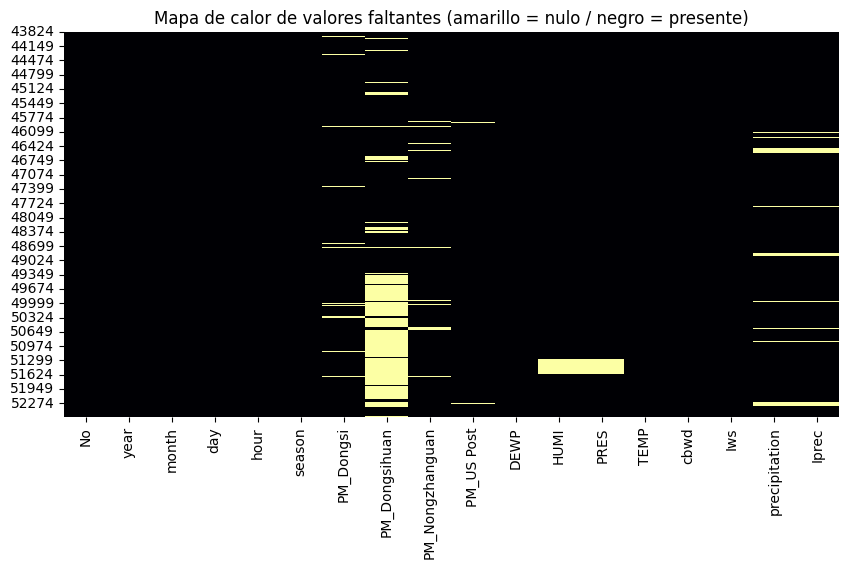

In [5]:
import seaborn as sns

# Contamos cuántos valores faltantes tiene la serie que nos interesa
n_faltantes = df_Beijing['PM_Nongzhanguan'].isna().sum()
print(f"Valores faltantes (NaN) en PM_Nongzhanguan: {n_faltantes}")
print("---"*17)
print("---"*17)
print("---"*17)

# Crear mapa de calor de valores nulos (agregando .isna() al DataFrame)
plt.figure(figsize=(10, 5))
sns.heatmap(df_Beijing.isna(), cbar=False, cmap="inferno")
plt.title(
    "Mapa de calor de valores faltantes (amarillo = nulo / negro = presente)"
)
plt.show()


## ¿Qué es interpolar y por qué es necesario hacerlo?

Al cargar datos reales, a veces faltan mediciones (aparecen como `NaN`, "Not a Number"). Una red neuronal **no puede entrenar con huecos** en los datos: necesita un número en cada posición.

La **interpolación lineal** rellena cada hueco dibujando una línea recta entre el valor anterior y el posterior disponibles:

```
valor real:   20        NaN        NaN        32
interpolado:  20   →    24    →    28    →   32      (sube de 4 en 4)
```

Es el rellenado más sencillo y razonable para series temporales suaves como la que estamos desarrollando. Se hace con un solo comando de pandas: `.interpolate()`.

In [6]:
# Interpolamos: pandas rellena cada hueco con una línea recta
# entre el valor anterior y el siguiente disponible
df_Beijing['PM_Nongzhanguan'] = df_Beijing['PM_Nongzhanguan'].interpolate()

print("Después de interpolar, faltantes:", df_Beijing['PM_Nongzhanguan'].isna().sum())
df_Beijing['PM_Nongzhanguan'].head(10)

Después de interpolar, faltantes: 0


,PM_Nongzhanguan
43824,8.0
43825,7.0
43826,7.0
43827,11.0
43828,5.0
43829,3.0
43830,6.0
43831,7.0
43832,9.0
43833,11.0


## Veamos los últimos 42 días de la serie



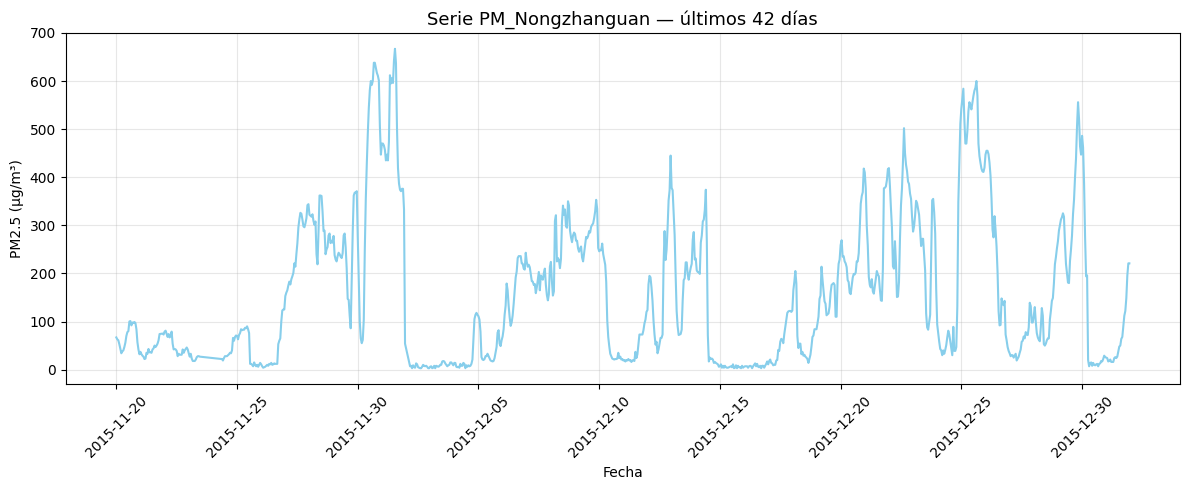

In [7]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# Creamos la columna de fecha combinando year, month, day y hour
df_Beijing['fecha'] = pd.to_datetime(df_Beijing[['year', 'month', 'day', 'hour']])

#  La asignamos como índice del DataFrame
df_Beijing = df_Beijing.set_index('fecha')

# Interpolamos valores faltantes en la serie
df_Beijing['PM_Nongzhanguan'] = df_Beijing['PM_Nongzhanguan'].interpolate(method='time')

# seleccionamos los últimos 42 días (42 días * 24 horas = 1008 filas)
ultimos_42_dias = df_Beijing['PM_Nongzhanguan'].iloc[-1008:]

# Graficamos con formato de fechas limpias en el eje X
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    ultimos_42_dias.index,
    ultimos_42_dias.values,
    color='skyblue',
    linewidth=1.5,
)

# Formato de fechas cada 5 días
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
plt.xticks(rotation=45)

# Etiquetas y título
ax.set_title('Serie PM_Nongzhanguan — últimos 42 días', fontsize=13)
ax.set_ylabel('PM2.5 (µg/m³)')
ax.set_xlabel('Fecha')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 2. Preparar los datos: la ventana deslizante


Una red neuronal necesita ejemplos del tipo entrada → respuesta correcta. Dado que solo tenemos una serie, la convertimos en muchos ejemplos con una técnica llamada ventana deslizante:

```
Serie:  [15, 14, 11, 19, 16, 21, 18, 16, 17, 16, 12, 18, 19, 24, ...]

Ejemplo 1: entrada = [15, 14, 11, 19, 16, 21, 18, 16, 17, 16, 12, 18]  → objetivo = 19
Ejemplo 2: entrada = [14, 11, 19, 16, 21, 18, 16, 17, 16, 12, 18, 19]  → objetivo = 24
Ejemplo 3: entrada = [11, 19, 16, 21, 18, 16, 17, 16, 12, 18, 19, 24]  → objetivo = ???
...
```

- Cada entrada tiene 12 horas (`input_hours = 12`): lo que la red está viendo.
- El objetivo es el valor de la hora siguiente: lo que la red debe aprender a predecir.
- La ventana avanza de 3 en 3 horas (`sample_gap = 3`) para generar más ejemplos de entrenamiento sin que se parezcan demasiado entre sí.

## División train / test

De los últimos 56 días (`series_days = 56` = 1344 horas) reservamos las últimas 48 horas (`test_hours`) para evaluar:

```
[────────────── 1296 h de ENTRENAMIENTO ──────────────][── 48 h de TEST ──]
                                                       ↑
                       (de aquí salen 36 predicciones: las 12 primeras horas
                        del test sirven como "arranque" y las 36 restantes
                        son lo que queremos pronosticar)
```

## ¿Por qué la entrada tiene "forma" (n, 12, 1)?

Keras exige que los datos de una RNN vengan en un arreglo de 3 dimensiones:

| Dimensión | Significado | Valor |
|---|---|---|
| `n` | número de ejemplos de entrenamiento | 428 |
| `12` | pasos de tiempo que ve la red (horas) | 12 |
| `1` | número de variables de entrada ("features") | 1 (solo la propia serie) |

Eso es lo que hace `get_keras_format_series`: convierte la lista de ventanas en un arreglo numpy con esa forma 3D.


In [8]:
def get_n_last_days(df, series_name, n_days):
    """Devuelve los últimos n_days días (horas) de una serie."""
    return df[series_name][-(24 * n_days):]

In [9]:
def get_keras_format_series(series):
    """Convierte una lista de ventanas en arreglo numpy de forma (n_ejemplos, pasos, 1)."""
    series = np.array(series)
    return series.reshape(series.shape[0], series.shape[1], 1)

def get_train_test_data(df, series_name, series_days, input_hours,
                        test_hours, sample_gap=3):
    """
    Corta la serie en ejemplos de entrenamiento (ventana deslizante)
    y reserva el final como conjunto de prueba.

    Devuelve:
      train_X     : arreglo (n_ejemplos, input_hours, 1)  entradas de entrenamiento
      test_X_init : las primeras input_hours del test  arranque del pronóstico
      train_y     : lista con el valor siguiente a cada ventana (objetivos)
      test_y      : las 36 horas reales que queremos pronosticar
    """
    forecast_series = get_n_last_days(df, series_name, series_days).values

    train = forecast_series[:-test_hours]      # todo menos el final
    test  = forecast_series[-test_hours:]      # las últimas 48 horas

    train_X, train_y = [], []

    # ventana deslizante: avanzamos sample_gap horas en cada ejemplo
    for i in range(0, train.shape[0] - input_hours, sample_gap):
        train_X.append(train[i:i + input_hours])       # las 12 horas vistas
        train_y.append(train[i + input_hours])          # la hora a predecir

    train_X = get_keras_format_series(train_X)

    test_X_init = test[:input_hours]   # 12 horas de arranque
    test_y      = test[input_hours:]   # 36 horas a pronosticar

    return train_X, test_X_init, train_y, test_y


# Parámetros del ejercicio 1
series_days = 56     #  últimos 56 días de la serie
input_hours = 12   # la red ve 12 horas para predecir la siguiente
test_hours  = 48   # reservamos 48 h al final (12 de arranque + 36 a predecir)

train_X, test_X_init, train_y, test_y = get_train_test_data(
    df_Beijing, 'PM_Nongzhanguan', series_days, input_hours, test_hours)

# ── Comprobaciones ────────────────────────────────────────────
print("Forma de train_X :", train_X.shape, "→ 428 ejemplos de 12 horas con 1 variable")
print("Forma de test_X_init:", test_X_init.shape, "→ 12 horas de arranque")
print("Longitud de test_y  :", len(test_y), "→ horas reales a pronosticar")
print()
print("Primer ejemplo de entrenamiento:")
print("  entrada (12 h):", train_X[0].flatten())
print("  objetivo (h+1):", train_y[0])


Forma de train_X : (428, 12, 1) → 428 ejemplos de 12 horas con 1 variable
Forma de test_X_init: (12,) → 12 horas de arranque
Longitud de test_y  : 36 → horas reales a pronosticar

Primer ejemplo de entrenamiento:
  entrada (12 h): [15. 14. 11. 19. 16. 21. 18. 16. 17. 16. 12. 18.]
  objetivo (h+1): 19.0


# 3. Teoría exprés: la RNN y sus hiperparámetros

## ¿Qué es una red neuronal recurrente (RNN)?

Una red "normal" (densa) olvida cada ejemplo en cuanto pasa al siguiente. Una **RNN** tiene una memoria interna: cuando procesa la hora 7, conserva un resumen de lo que vio en las horas 1 a 6. Así puede aprender patrones como cuando la serie lleva subiendo varias horas, probablemente siga subiendo.

- Unidades ocultas (`cell_units`) = el tamaño de esa memoria. Más unidades = memoria más rica, pero también más parámetros que entrenar (más lento y más riesgo de sobreajuste).
- Capa `Dense(1)` = la "salida": convierte la memoria final en un único número: la predicción de la hora siguiente.

## Los tres hiperparámetros que vamos a experimentar

Un **hiperparámetro** es un número que *nosotros elegimos* antes de entrenar (la red no lo aprende por sí sola):

| Hiperparámetro | ¿Qué significa? | Efecto de aumentarlo |
|---|---|---|
| **`cell_units`** (unidades ocultas) | Tamaño de la memoria de la RNN | Modelo más expresivo… pero más lento y propenso a sobreajuste |
| **`epochs`** (épocas) | Cuántas veces la red ve **todo** el conjunto de entrenamiento | Más aprendizaje… pero después de cierto punto memoriza en vez de generalizar |
| **`batch_size`** (tamaño de lote) | Cuántos ejemplos procesa antes de actualizar sus pesos | Más pequeño = actualizaciones más frecuentes y ruidosas (a veces aprende mejor); más grande = más estable y rápido por época |




En este notebook guardamos, además de la pérdida de entrenamiento, una pérdida de validación (`val_loss`), calculada sobre un 10% de datos que la red *no* usa para aprender. Si las dos curvas se separan ("tijera" abierta), tenemos sobreajuste.


 FUNCIÓN DE ENTRENAMIENTO (RNN simple)
    Construye y entrena una RNN simple con Keras.

    train_X      : datos de entrada, forma (n_ejemplos, pasos, 1)
    train_y      : valores a predecir (hora siguiente)
    cell_units   : nº de unidades ocultas (tamaño de la memoria)
    epochs       : nº de veces que la red ve todo el entrenamiento
    batch_size   : ejemplos por cada actualización de pesos
    validation_split: fracción de datos reservada para medir generalización


In [10]:
# ═ FUNCIÓN DE ENTRENAMIENTO (RNN simple) ═
def fit_SimpleRNN(train_X, train_y, cell_units, epochs, batch_size=64,
                  validation_split=0.1):

    model = Sequential()                                        # contenedor vacío
    model.add(SimpleRNN(cell_units,                             # la capa recurrente
                        input_shape=(train_X.shape[1], 1)))      # (12 pasos, 1 variable)
    model.add(Dense(1))                                          # salida: 1 número

    model.compile(loss='mean_squared_error', optimizer='adam')  # cómo medir y cómo aprender
    history = model.fit(train_X, np.array(train_y),
                        epochs=epochs,
                        batch_size=batch_size,
                        validation_split=validation_split,
                        verbose=0)                              # 0 = no imprime barra (más limpio)
    return model, history


In [11]:
# ═ FUNCIÓN DE PRONÓSTICO PASO A PASO ═
def predict(X_init, n_steps, model):

    X_init = np.array(X_init).copy().reshape(1, -1, 1)
    preds = []

    for _ in range(n_steps):
        pred = model.predict(X_init, verbose=0)   # predicción de la hora siguiente
        preds.append(pred[0, 0])                 # guardamos el número
        X_init[:, :-1, :] = X_init[:, 1:, :]       # desplazamos la ventana
        X_init[:, -1, :]  = pred                   # insertamos la predicción nueva

    return np.array(preds)

 FUNCIÓN DE PRONÓSTICO PASO A PASO

    Genera n_steps predicciones futuras de forma ITERATIVA:
    1) predice la hora siguiente a partir de la ventana actual,
    2) desplaza la ventana un paso e inserta la predicción al final,
    3) repite.
    (Las predicciones se reutilizan como entrada: se acumula error a largo plazo.)
  

### **Revisanmos métricas y graficamos**

In [12]:
# ═ MÉTRICAS DE ERROR ═
def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true).flatten()
    mae  = np.mean(np.abs(y_true - y_pred))                  # Error Absoluto Medio
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))         # Raíz Error Cuadrático Medio
    return mae, rmse


# ═ PRONOSTICAR + DIBUJAR + MEDIR ═
def predict_and_plot(X_init, y, model, title):
    y_preds = predict(X_init, n_steps=len(y), model=model)
    y_true  = np.array(y).flatten()
    mae, rmse = compute_metrics(y_true, y_preds)

    start_range   = range(1, input_hours + 1)                # horas de "arranque"
    predict_range = range(input_hours, test_hours)           # horas pronosticadas

    plt.figure(figsize=(10, 4))
    plt.plot(start_range,   np.array(X_init).flatten(), 'k-',  label='Arranque (12 h reales)')
    plt.plot(predict_range, y_true,  color='orange',           label='Valores reales')
    plt.plot(predict_range, y_preds, color='teal', linestyle='--', label='Predicciones')
    plt.axvline(input_hours + 0.5, color='gray', linestyle=':', alpha=0.6)

    plt.title(title)
    plt.xlabel('Hora')
    plt.ylabel('PM2.5')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print(f"  → MAE  = {mae:.2f}  µg/m³")
    print(f"  → RMSE = {rmse:.2f}  µg/m³")
    return y_preds, mae, rmse

In [13]:
# Diccionario donde iremos guardando los resultados de cada configuración
results = {}

# Tamaño del conjunto de validación para contexto
n_train = train_X.shape[0]
print(f"Ejemplos de entrenamiento: {n_train}  →  validación (10%): {int(n_train*0.1)}")


Ejemplos de entrenamiento: 428  →  validación (10%): 42


# 4. Configuración 1: modelo base - sencillo

Hiperparámetros: `cell_units = 10` · `epochs = 10` · `batch_size = 64`

Empezamos con lo mínimo como se solicita: es decir, una memoria pequeña y pocas pasadas sobre los datos.

Un modelo así apenas tiene tiempo de aprender: probablemente dé una predicción casi plana (subajuste / underfitting). Sirve como línea base: cualquier mejora posterior debe superar estos números.

> Con 428 ejemplos y lotes de 64, cada época hace ⌈428/64⌉ ≈ 7 actualizaciones de pesos; en 10 épocas solo 70 actualizaciones en total. Es poquísimo para una red neuronal.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


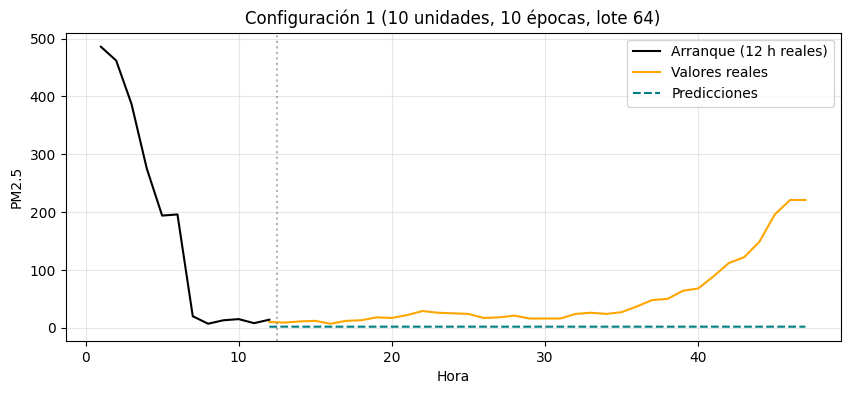

  → MAE  = 48.55  µg/m³
  → RMSE = 76.50  µg/m³


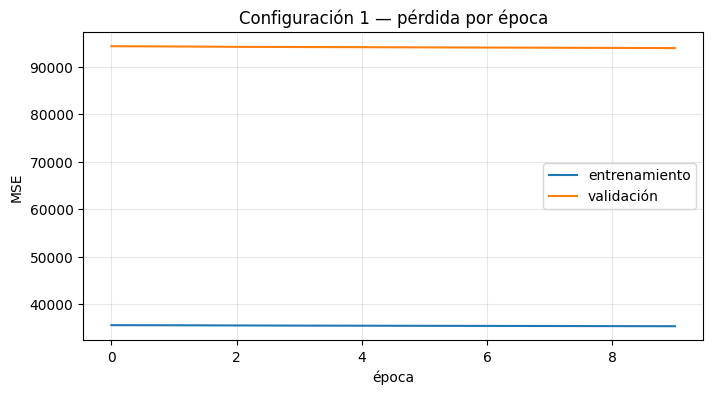

In [14]:
# ─Configuración 1 baseline ─
modelo1, historial1 = fit_SimpleRNN(train_X, train_y,
                                    cell_units=10, epochs=10, batch_size=64)

# Evaluamos sobre el test y dibujamos
y_pred_1, mae_1, rmse_1 = predict_and_plot(
    test_X_init, test_y, modelo1,
    'Configuración 1 (10 unidades, 10 épocas, lote 64)')

results['C1: 10u / 10ép / lote64'] = (mae_1, rmse_1)

# Curvas de pérdida
plt.figure(figsize=(8, 4))
plt.plot(historial1.history['loss'], label='entrenamiento')
plt.plot(historial1.history['val_loss'], label='validación')
plt.title('Configuración 1 — pérdida por época')
plt.xlabel('época'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


# 5 — Configuración 2: modelo intermedio

Hiperparámetros: `cell_units = 32` · `epochs = 100` · `batch_size = 32`

Aumentamos los tres hiperparámetros:

- 32 unidades: la memoria puede codificar patrones diarios más finos.
- 100 épocas: la red ve el dataset cien veces (1400 actualizaciones de pesos) — debería aprender lo esencial del patrón.
- Lote 32: actualizaciones más frecuentes (≈14 por época) y más ruidosas, lo que suele ayudar a escapar de soluciones mediocres.



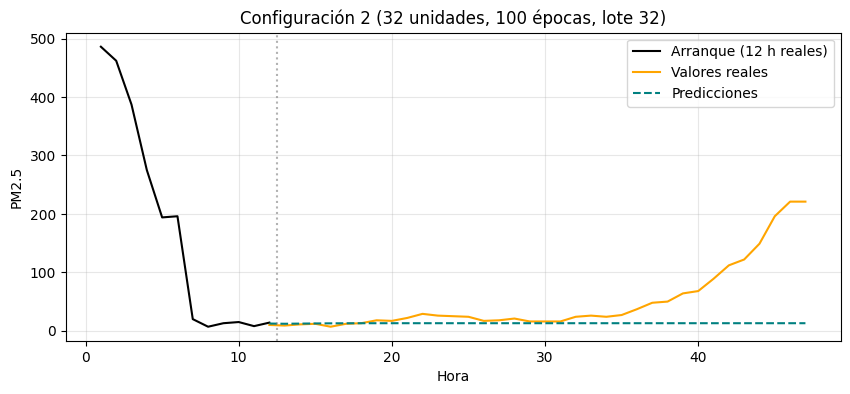

  → MAE  = 38.33  µg/m³
  → RMSE = 69.99  µg/m³


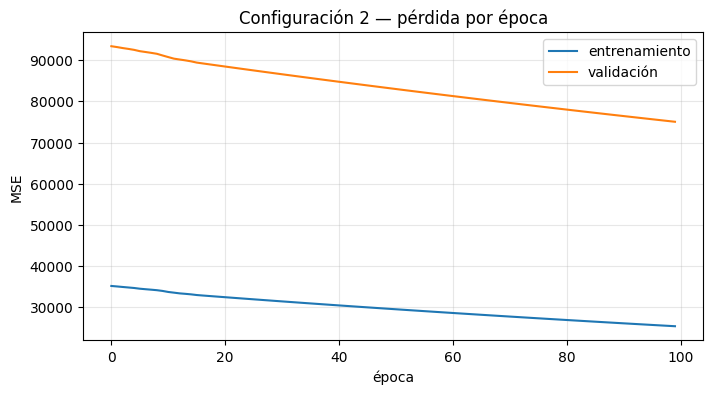

In [15]:
# ── Configuración 2: intermedia
modelo2, historial2 = fit_SimpleRNN(train_X, train_y,
                                    cell_units=32, epochs=100, batch_size=32)

y_pred_2, mae_2, rmse_2 = predict_and_plot(
    test_X_init, test_y, modelo2,
    'Configuración 2 (32 unidades, 100 épocas, lote 32)')

results['C2: 32u / 100ép / lote32'] = (mae_2, rmse_2)

plt.figure(figsize=(8, 4))
plt.plot(historial2.history['loss'], label='entrenamiento')
plt.plot(historial2.history['val_loss'], label='validación')
plt.title('Configuración 2 — pérdida por época')
plt.xlabel('época'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


#  6 — Configuración 3: modelo complejo

Hiperparámetros: `cell_units = 64` · `epochs = 300` · `batch_size = 16`

Aquí llevamos la complejidad al máximo razonable del ejercicio:

- 64 unidades: memoria muy rica → muchos parámetros.
- 300 épocas: 300 × 27 ≈ 8100 actualizaciones.
- Lote 16: el lote más pequeño de los tres (más ruido en el aprendizaje).

Riesgos a vigilar:
1. Tiempo de entreno: esta celda tarda notablemente más que las anteriores. Si tardara demasiado en Colab, baja las épocas a 150.
2. Sobreajuste: vigila la curva de validación. Si `val_loss` empieza a subir mientras la de entrenamiento sigue bajando, la red está memorizando el entrenamiento y perdiendo capacidad de generalizar.


https://developers.google.com/machine-learning/crash-course/overfitting/overfitting?hl=es-419

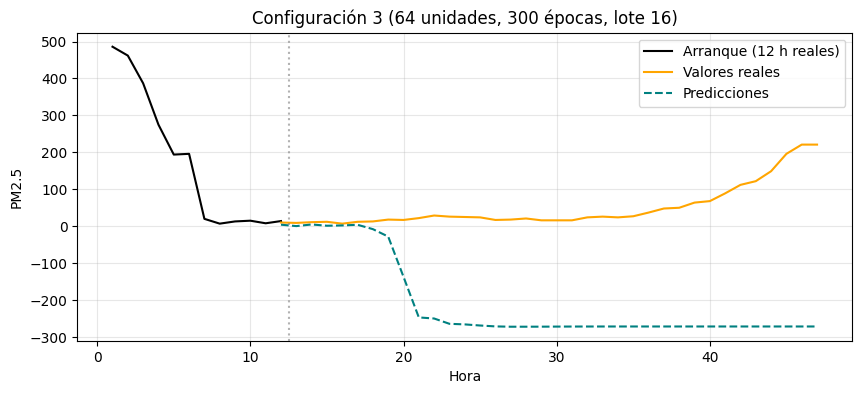

  → MAE  = 256.71  µg/m³
  → RMSE = 294.61  µg/m³


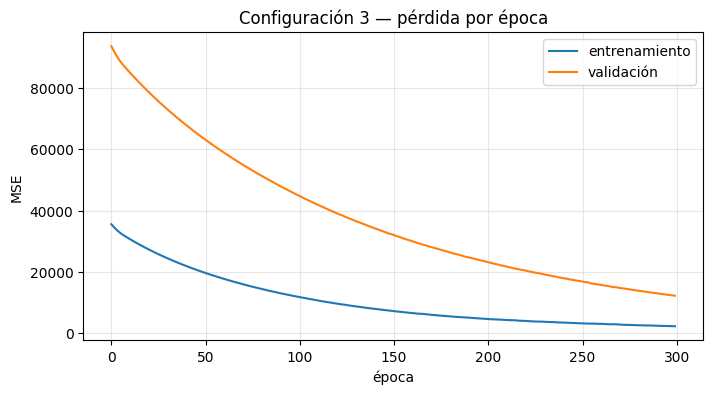

In [16]:
# ── Configuración 3: compleja
# cabe decir que si tarda varios minutos en CPU de Colab este reduce epochs si hace falta
modelo3, historial3 = fit_SimpleRNN(train_X, train_y,
                                    cell_units=64, epochs=300, batch_size=16)

y_pred_3, mae_3, rmse_3 = predict_and_plot(
    test_X_init, test_y, modelo3,
    'Configuración 3 (64 unidades, 300 épocas, lote 16)')

results['C3: 64u / 300ép / lote16'] = (mae_3, rmse_3)

plt.figure(figsize=(8, 4))
plt.plot(historial3.history['loss'], label='entrenamiento')
plt.plot(historial3.history['val_loss'], label='validación')
plt.title('Configuración 3 — pérdida por época')
plt.xlabel('época'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


# 7 — Comparación de resultados

## Tabla de métricas

Aquí reunimos los MAE y RMSE de las tres configuraciones.

- **MAE** bajo = acierto típico bueno (en µg/m³).
- **RMSE** bajo = no comete errores catastróficos (si RMSE >> MAE, hay predicciones muy desviadas).


In [17]:
# Tabla comparativa de métricas
tabla = pd.DataFrame(results, index=['MAE', 'RMSE']).T
tabla = tabla.round(2)
tabla = tabla.sort_values('MAE')   # de mejor a peor
print("=== Comparación de configuraciones (ordenadas por MAE) ===")
tabla


=== Comparación de configuraciones (ordenadas por MAE) ===


,MAE,RMSE
C2: 32u / 100ép / lote32,38.33,69.99
C1: 10u / 10ép / lote64,48.55,76.50
C3: 64u / 300ép / lote16,256.71,294.61


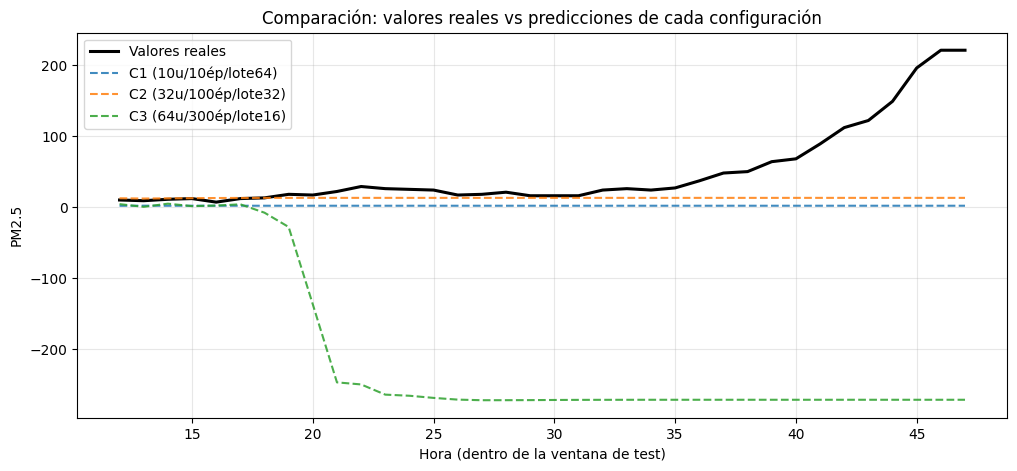

🏆 Mejor configuración según MAE: C2: 32u / 100ép / lote32
                             MAE    RMSE
C2: 32u / 100ép / lote32   38.33   69.99
C1: 10u / 10ép / lote64    48.55   76.50
C3: 64u / 300ép / lote16  256.71  294.61


In [18]:
# Gráfica comparativa: valores reales vs predicciones de las 3 configuraciones
predict_range = range(input_hours, test_hours)

plt.figure(figsize=(12, 5))
plt.plot(predict_range, test_y, color='black', linewidth=2.2, label='Valores reales')
plt.plot(predict_range, y_pred_1, '--', alpha=0.85, label='C1 (10u/10ép/lote64)')
plt.plot(predict_range, y_pred_2, '--', alpha=0.85, label='C2 (32u/100ép/lote32)')
plt.plot(predict_range, y_pred_3, '--', alpha=0.85, label='C3 (64u/300ép/lote16)')

plt.title('Comparación: valores reales vs predicciones de cada configuración')
plt.xlabel('Hora (dentro de la ventana de test)')
plt.ylabel('PM2.5')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Determinamos la mejor configuración según el MAE
mejor = tabla.index[0]
print(" Mejor configuración según MAE:", mejor)
print(tabla)


In [19]:
# Número de parámetros entrenables de cada modelo (complejidad computacional)
for nombre, m in [('C1', modelo1), ('C2', modelo2), ('C3', modelo3)]:
    print(f"{nombre}: {m.count_params():,} parámetros entrenables")


C1: 131 parámetros entrenables
C2: 1,121 parámetros entrenables
C3: 4,289 parámetros entrenables


## Análisis del impacto de los hiperparámetros (guía de interpretación)

Compara tus curvas y métricas con estos patrones típicos:

### 1. Efecto de las épocas y unidades (C1 → C2)
- En **C1** la red apenas aprende: sus predicciones son casi una línea recta y las curvas de pérdida aún no han convergido. **Subajuste**: el modelo es demasiado simple *o* se entrenó muy poco tiempo.
- En **C2** la predicción ya sigue la forma de la curva real (subidas y bajadas) y las curvas de pérdida estabilizan en un valor bajo con validación cercana a entrenamiento → **buen equilibrio**.

### 2. Sobreajuste en C3 (mira la "tijera" de las curvas)
- Si la pérdida de **entrenamiento** sigue bajando pero la de **validación** se estanca o sube, la red está memorizando las 428 ventanas de entrenamiento.
- Síntoma típico: predicciones que se pegan demasiado al último valor visto ("empiezan bien y luego se achatan"), porque el modelo memorizó patrones poco generales.

### 3. Interpretación de MAE vs RMSE
- Si **RMSE >> MAE**: hay algunas horas con error enorme (la predicción desvarió a mitad del horizonte). Es normal en pronósticos iterativos: los errores se **acumulan** al reutilizar las propias predicciones como entrada.
- C1 suele tener MAE alto (mala predicción global); C2/C3 lo reducen, pero si C3 empeora el RMSE sin mejorar el MAE, estamos pagando complejidad sin ganar precisión.

### 4. Eficiencia computacional
Más unidades y épocas = más parámetros y más tiempo por época. C1 entrena en segundos pero es inútil; C3 puede costar 10–20 veces más que C2. **La mejor arquitectura no es la más precisa, sino la mejor relación precisión/tiempo.**

Conclusiones de IA Gemini


#  8. Conclusiones

La arquitectura final seleccionada es la  Configuración 2 (32 unidades ocultas, 100 épocas, lote 32). La justificación es porque:

*	Precisión: obtiene un MAE de 38.33 µg/m³ y un RMSE de 69.99 µg/m³, superando claramente al modelo base C1 (48.55 µg/m³ de MAE y 76.50 µg/m³ de RMSE), que sufría subajuste al quedarse estancado cerca de cero.
*	Generalización: sus curvas de entrenamiento y validación descienden de forma estable y paralela sin separarse ni rebotar, señal de que el modelo aprende patrones reales sin memorizar el ruido.
*	Estabilidad y eficiencia: supera ampliamente el error en test de C3 (256.71 µg/m³ de MAE y 294.61 µg/m³ de RMSE) con menos parámetros y mucho menos tiempo de entrenamiento. C3 solo consigue una pérdida de entrenamiento más baja, pero al realizar el pronóstico recursivo se desestabiliza y cae hacia valores negativos imposibles (-270 µg/m³) → sobreajuste e inestabilidad en extrapolación.

>No obstante, es importante decir que las 3 configuraciones pierden precisión al avanzar en las 36 horas pronosticadas. Por ello, acá comprobamos que más complejidad ≠ más precisión: pasado cierto punto aparece el Overfitting.



